# Ideal FTS interferograms

Illustration of the FOSSIL measurement principle with an ideal FTS (no
systematics): each output sees

$P(x) = \sum_\nu w(\nu)\,[I_1 + I_2 + s\,(I_1 - I_2)\cos(2\pi\nu x/c)]\,\Delta\nu$,

with $x$ the optical path difference ($x = 2\delta$ for mirror position $\delta$ in the
Step2 formula; the factor is a TBD config parameter),
$s = +1$ for the L output and $-1$ for the R output, and $w(\nu)$ the
band of the detector unit (LF below 200 GHz, HF above). OPD range and
sampling are TBD placeholders from `configs/baseline.toml`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt

from fossil_sim.config import load_config
from fossil_sim.ifg import (
    differential_spectrum,
    interferogram,
    mirror_positions_m,
    opd_samples_m,
)
from fossil_sim.instrument import detector_units, frequency_grid_ghz
from fossil_sim.spectra import blackbody_mjy_sr, y_distortion_mjy_sr

config = load_config(Path.cwd().parent / "configs" / "baseline.toml")
freq_ghz = frequency_grid_ghz(config.instrument)
opd_m = opd_samples_m(config.ifg)
delta_m = mirror_positions_m(config.ifg)
dus = {du.name: du for du in detector_units(config.instrument)}
print(
    f"{freq_ghz.size} frequency bins, {delta_m.size} samples, "
    f"OPD_max = {1e3 * opd_m.max():.1f} mm, mirror δ_max = {1e3 * delta_m.max():.1f} mm "
    f"(OPD / δ = {config.ifg.opd_per_mirror_position}, TBD)"
)

130 frequency bins, 512 samples, OPD_max = 10.0 mm, mirror δ_max = 5.0 mm (OPD / δ = 2.0, TBD)


## Mode B10: sky on Port 1, BBIR on Port 2

Sky = CMB blackbody plus a Compton-y distortion with $y = 10^{-5}$ (exaggerated
for visibility); BBIR at the 2.725 K set-point.

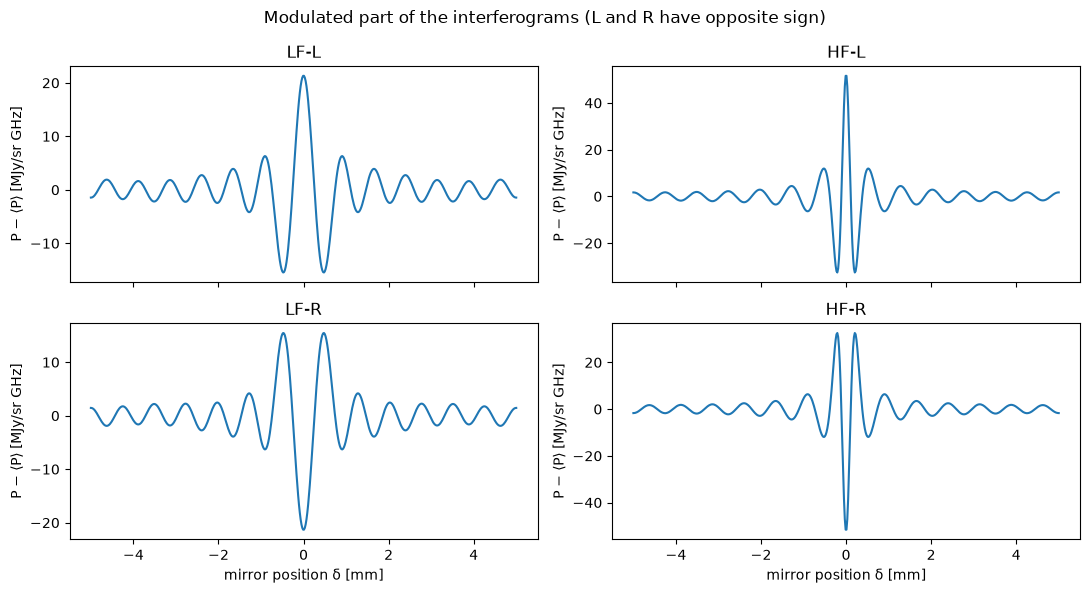

In [2]:
y = 1e-5
sky_mjy_sr = blackbody_mjy_sr(freq_ghz, config.sky.t_cmb_k) + y_distortion_mjy_sr(
    freq_ghz, y, config.sky.t_cmb_k
)
bbir_mjy_sr = blackbody_mjy_sr(freq_ghz, config.bbir.setpoints_k[0])

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for ax, name in zip(axes.ravel(), dus):
    ifg = interferogram(freq_ghz, sky_mjy_sr, bbir_mjy_sr, dus[name], opd_m)
    ax.plot(1e3 * delta_m, ifg - ifg.mean())
    ax.set(title=name, ylabel="P − ⟨P⟩ [MJy/sr GHz]")
for ax in axes[1]:
    ax.set_xlabel("mirror position δ [mm]")
fig.suptitle("Modulated part of the interferograms (L and R have opposite sign)")
fig.tight_layout()

## Back to the spectrum

The recovered differential spectrum is dominated by the residual monopole
(the BBIR set-point differs from $T_\mathrm{CMB}$ by 0.5 mK). Subtracting the
known blackbody difference leaves the y distortion.

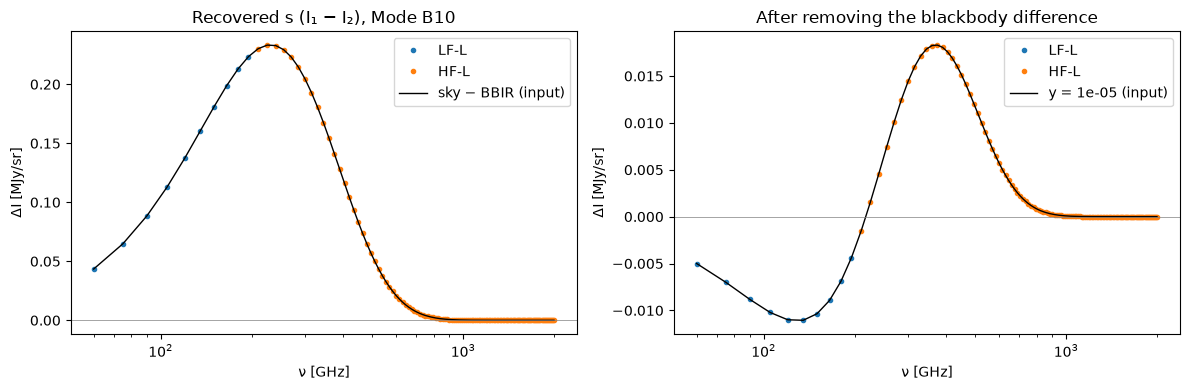

In [3]:
blackbody_difference_mjy_sr = (
    blackbody_mjy_sr(freq_ghz, config.sky.t_cmb_k) - bbir_mjy_sr
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in ("LF-L", "HF-L"):
    du = dus[name]
    ifg = interferogram(freq_ghz, sky_mjy_sr, bbir_mjy_sr, du, opd_m)
    recovered = differential_spectrum(freq_ghz, ifg, du, opd_m)
    axes[0].plot(freq_ghz, recovered, "o", ms=3, label=name)
    axes[1].plot(
        freq_ghz, recovered - blackbody_difference_mjy_sr, "o", ms=3, label=name
    )
axes[0].plot(freq_ghz, sky_mjy_sr - bbir_mjy_sr, "k-", lw=1, label="sky − BBIR (input)")
axes[0].set(title="Recovered s (I₁ − I₂), Mode B10")
axes[1].plot(
    freq_ghz,
    y_distortion_mjy_sr(freq_ghz, y, config.sky.t_cmb_k),
    "k-",
    lw=1,
    label=f"y = {y:g} (input)",
)
axes[1].set(title="After removing the blackbody difference")
for ax in axes:
    ax.axhline(0, color="gray", lw=0.5)
    ax.set(xscale="log", xlabel="ν [GHz]", ylabel="ΔI [MJy/sr]")
    ax.legend()
fig.tight_layout()